# Mini-projet ML — GoEmotions : amélioration progressive de l'accuracy

**Objectif :** montrer la démarche complète d'amélioration des performances :

1. Classification initiale sur **28 classes (27 émotions + neutral)** → accuracy autour de 0,51 sur dev.
2. Regroupement par **mapping en 3 sentiments** → accuracy autour de 0,69 sur dev.
3. Classification binaire **positive / negative** avec suppression de `neutral` + **undersampling** → accuracy autour de 0,83 sur dev.

Le notebook garde les **5 modèles ML** demandés : Logistic Regression, Naive Bayes, Linear SVM, Decision Tree, Random Forest.


## 1) Installation et importation des bibliothèques

Exécuter l'installation seulement si une bibliothèque manque.

In [3]:
import os
import re
import string
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

## 2) Chargement des données

Vérifie que le chemin `base_path` correspond au dossier qui contient : `train.tsv`, `dev.tsv`, `test.tsv`, `emotions.txt`.

In [4]:
# Le notebook se trouve dans notebooks/ et les données dans data/.
from pathlib import Path

candidate_paths = [Path.cwd() / "data", Path.cwd().parent / "data"]
base_path = next((p.resolve() for p in candidate_paths if (p / "train.tsv").is_file()), None)
if base_path is None:
    raise FileNotFoundError("Dossier data introuvable. Lancez Jupyter depuis la racine du projet ou depuis notebooks/.")

print("Dossier des données :", base_path)


Dossier des données : C:\Users\TBAR9A\Desktop\MPDS\ML\Mini-Projet\GoEmotions_MiniProjet\data


In [5]:
# Les TSV GoEmotions n'ont pas d'en-tête.
columns = ["text", "labels", "id"]

train_path = base_path / "train.tsv"
dev_path = base_path / "dev.tsv"
test_path = base_path / "test.tsv"
emotions_path = base_path / "emotions.txt"

required_files = [train_path, dev_path, test_path, emotions_path]
missing_files = [str(path) for path in required_files if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Fichiers manquants : " + ", ".join(missing_files))

train = pd.read_csv(train_path, sep="\t", header=None, names=columns)
dev = pd.read_csv(dev_path, sep="\t", header=None, names=columns)
test = pd.read_csv(test_path, sep="\t", header=None, names=columns)

with open(emotions_path, "r", encoding="utf-8") as f:
    emotions = [line.strip() for line in f]

print("Train :", train.shape)
print("Dev   :", dev.shape)
print("Test  :", test.shape)
print("Labels (27 émotions + neutral) :", len(emotions))
train.head()


Train : (43410, 3)
Dev   : (5426, 3)
Test  : (5427, 3)
Labels (27 émotions + neutral) : 28


,text,labels,id
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj
3,To make her feel threatened,14,ed7ypvh
4,Dirty Southern Wankers,3,ed0bdzj


## 3) Préparation mono-label

GoEmotions est à l'origine un jeu **multi-label**. Pour utiliser les modèles multi-classes classiques, ce projet conserve **le premier label** de chaque exemple. Les exemples multi-label ne sont donc pas supprimés : ils sont ramenés à une seule cible selon cette règle.


In [6]:
def first_label(label_value):
    label_str = str(label_value)
    return int(label_str.split(",")[0])

for df in [train, dev, test]:
    df["label_id"] = df["labels"].apply(first_label)
    df["emotion"] = df["label_id"].apply(lambda x: emotions[int(x)])

train_single = train.copy()
dev_single = dev.copy()
test_single = test.copy()

print(train_single[["text", "labels", "label_id", "emotion"]].head())
print("Nombre de classes émotion :", train_single["emotion"].nunique())

                                                text labels  label_id  \
0  My favourite food is anything I didn't have to...     27        27   
1  Now if he does off himself, everyone will thin...     27        27   
2                     WHY THE FUCK IS BAYLESS ISOING      2         2   
3                        To make her feel threatened     14        14   
4                             Dirty Southern Wankers      3         3   

     emotion  
0    neutral  
1    neutral  
2      anger  
3       fear  
4  annoyance  
Nombre de classes émotion : 28


## 4) Analyse exploratoire rapide

In [7]:
# Valeurs manquantes
print("Valeurs manquantes train :")
print(train_single.isnull().sum())

# Doublons selon le texte
print("\nDoublons train selon text :", train_single.duplicated(subset=["text"]).sum())
print("Doublons dev selon text   :", dev_single.duplicated(subset=["text"]).sum())
print("Doublons test selon text  :", test_single.duplicated(subset=["text"]).sum())

Valeurs manquantes train :
text        0
labels      0
id          0
label_id    0
emotion     0
dtype: int64

Doublons train selon text : 183
Doublons dev selon text   : 3
Doublons test selon text  : 6


In [8]:
for df in [train_single, dev_single, test_single]:
    df["text_length"] = df["text"].apply(lambda x: len(str(x)))
    df["word_count"] = df["text"].apply(lambda x: len(str(x).split()))

train_single[["text_length", "word_count"]].describe()

,text_length,word_count
count,43410.000000,43410.000000
mean,68.400875,12.840175
std,36.721898,6.701597
min,2.000000,1.000000
25%,38.000000,7.000000
50%,65.000000,12.000000
75%,96.000000,18.000000
max,703.000000,33.000000


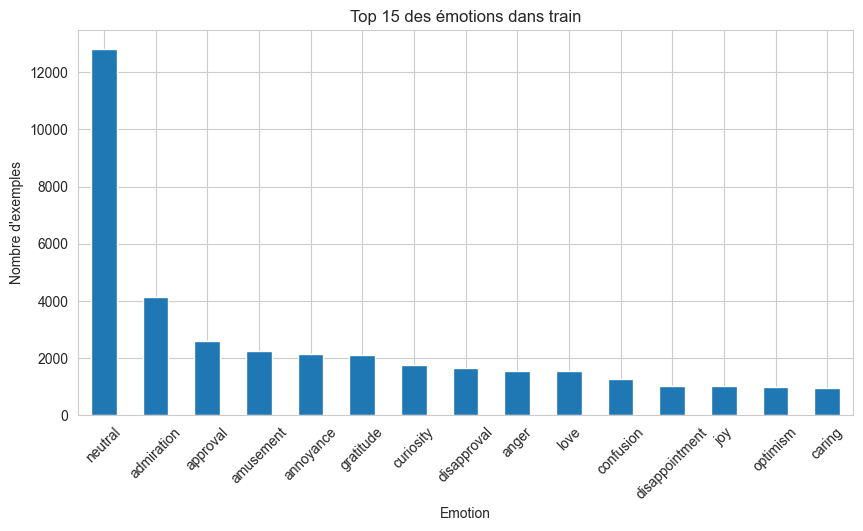

In [9]:
plt.figure(figsize=(10,5))
train_single["emotion"].value_counts().head(15).plot(kind="bar")
plt.title("Top 15 des émotions dans train")
plt.xlabel("Emotion")
plt.ylabel("Nombre d'exemples")
plt.xticks(rotation=45)
plt.show()

## 5) Prétraitement du texte

On applique un nettoyage léger : minuscules, suppression des liens, mentions, hashtags, chiffres et ponctuation. Ici on ne supprime pas les stopwords, car certains mots courts peuvent aider la classification de sentiment.

In [10]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#\w+", "", text)
    text = re.sub(r"\d+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

for df in [train_single, dev_single, test_single]:
    df["clean_text"] = df["text"].apply(clean_text)

train_single[["text", "clean_text"]].head(10)

,text,clean_text
0,My favourite food is anything I didn't have to...,my favourite food is anything i didnt have to ...
1,"Now if he does off himself, everyone will thin...",now if he does off himself everyone will think...
2,WHY THE FUCK IS BAYLESS ISOING,why the fuck is bayless isoing
3,To make her feel threatened,to make her feel threatened
4,Dirty Southern Wankers,dirty southern wankers
5,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,omg peyton isnt good enough to help us in the ...
6,Yes I heard abt the f bombs! That has to be wh...,yes i heard abt the f bombs that has to be why...
7,We need more boards and to create a bit more s...,we need more boards and to create a bit more s...
8,Damn youtube and outrage drama is super lucrat...,damn youtube and outrage drama is super lucrat...
9,It might be linked to the trust factor of your...,it might be linked to the trust factor of your...


## 6) Fonctions communes : undersampling, modèles, évaluation

L'**undersampling** sert à équilibrer les classes en réduisant les classes majoritaires au même nombre que la classe minoritaire. On l'applique seulement sur le **train**, jamais sur `dev` ni `test`.

In [11]:
def undersample_dataframe(df, target_col, random_state=42):
    # Équilibre les classes par undersampling sur le DataFrame d'entraînement
    min_count = df[target_col].value_counts().min()
    balanced_df = (
        df.groupby(target_col, group_keys=False)
          .apply(lambda x: x.sample(n=min_count, random_state=random_state))
          .sample(frac=1, random_state=random_state)
          .reset_index(drop=True)
    )
    return balanced_df


def get_models():
    # Retourne les 5 modèles ML demandés
    return {
        "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42),
        "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
        "Linear SVM": LinearSVC(class_weight="balanced", random_state=42),
        "Decision Tree": DecisionTreeClassifier(max_depth=40, min_samples_split=10, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
    }


def train_and_evaluate(X_train, y_train, X_dev, y_dev, max_features=30000, ngram_range=(1,2)):
    # Vectorisation TF-IDF + entraînement + évaluation
    vectorizer = TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )
    
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_dev_tfidf = vectorizer.transform(X_dev)
    
    trained_models = {}
    results = []
    
    for name, model in get_models().items():
        print("Entraînement :", name)
        model.fit(X_train_tfidf, y_train)
        y_pred = model.predict(X_dev_tfidf)
        
        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_dev, y_pred),
            "Precision": precision_score(y_dev, y_pred, average="weighted", zero_division=0),
            "Recall": recall_score(y_dev, y_pred, average="weighted", zero_division=0),
            "F1-score": f1_score(y_dev, y_pred, average="weighted", zero_division=0)
        })
        trained_models[name] = model
    
    results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
    return results_df, vectorizer, trained_models


def plot_results(results_df, title):
    plt.figure(figsize=(9,5))
    sns.barplot(data=results_df, x="Accuracy", y="Model")
    plt.title(title)
    plt.xlim(0, 1)
    plt.show()

# Expérience 1 — Classification fine sur 28 classes (27 émotions + neutral)

Cette première expérience utilise les 27 émotions et la classe neutral (28 classes). C'est le problème le plus difficile, donc l'accuracy est naturellement plus faible.

In [12]:
# Cible = émotion fine à 28 classes (27 émotions + neutral)
X_train_28 = train_single["clean_text"]
y_train_28 = train_single["emotion"]

X_dev_28 = dev_single["clean_text"]
y_dev_28 = dev_single["emotion"]

print("Nombre de classes y_train_28 :", y_train_28.nunique())
print(y_train_28.value_counts().head())

Nombre de classes y_train_28 : 28
emotion
neutral       12823
admiration     4130
approval       2596
amusement      2244
annoyance      2138
Name: count, dtype: int64


In [13]:
results_28, vectorizer_28, models_28 = train_and_evaluate(
    X_train_28, y_train_28,
    X_dev_28, y_dev_28,
    max_features=30000,
    ngram_range=(1,2)
)

results_28

Entraînement : Logistic Regression
Entraînement : Multinomial Naive Bayes
Entraînement : Linear SVM
Entraînement : Decision Tree
Entraînement : Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.507925,0.531469,0.507925,0.447442
1,Decision Tree,0.473830,0.458198,0.473830,0.396011
2,Linear SVM,0.440656,0.468850,0.440656,0.440411
3,Logistic Regression,0.420752,0.503470,0.420752,0.420677
4,Multinomial Naive Bayes,0.378916,0.498847,0.378916,0.265341


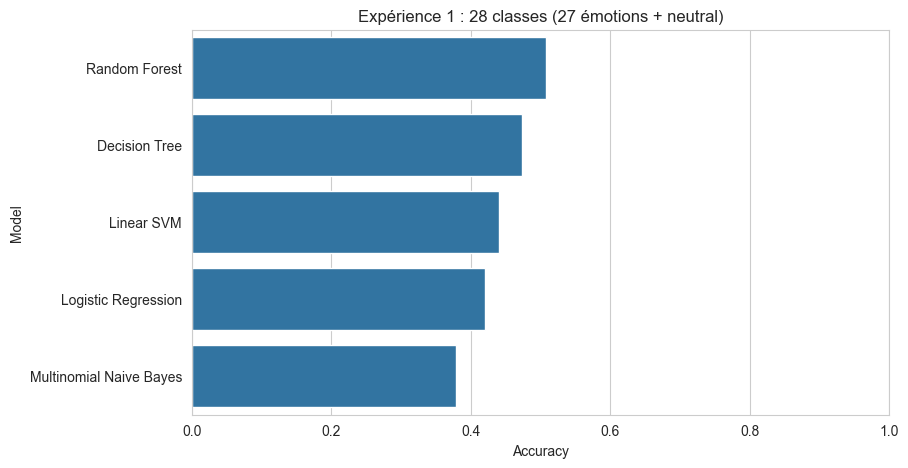

In [14]:
plot_results(results_28, "Expérience 1 : 28 classes (27 émotions + neutral)")

# Expérience 2 — Mapping 28 labels (27 émotions + neutral) → 3 sentiments

Le fichier `sentiment_mapping.json` regroupe les labels en `positive`, `negative` et `neutral`. Dans ce projet, `neutral` inclut le label `neutral` et les quatre émotions ambiguës `confusion`, `curiosity`, `realization` et `surprise`.


In [15]:
# Chargement du mapping 3 sentiments depuis data/sentiment_mapping.json
import json

mapping_path = base_path / "sentiment_mapping.json"
with open(mapping_path, "r", encoding="utf-8") as f:
    sentiment_groups = json.load(f)

emotion_to_sentiment = {
    emotion: sentiment
    for sentiment, emotion_list in sentiment_groups.items()
    for emotion in emotion_list
}

unmapped_emotions = sorted(set(emotions) - set(emotion_to_sentiment))
if unmapped_emotions:
    raise ValueError(f"Émotions sans mapping : {unmapped_emotions}")

for df in [train_single, dev_single, test_single]:
    df["sentiment"] = df["emotion"].map(emotion_to_sentiment)

print("Nombre de classes sentiment :", train_single["sentiment"].nunique())
print(train_single["sentiment"].value_counts())
train_single[["emotion", "sentiment"]].head(10)


Nombre de classes sentiment : 3
sentiment
neutral     17312
positive    16948
negative     9150
Name: count, dtype: int64


,emotion,sentiment
0,neutral,neutral
1,neutral,neutral
2,anger,negative
3,fear,negative
4,annoyance,negative
5,surprise,neutral
6,gratitude,positive
7,desire,positive
8,admiration,positive
9,neutral,neutral


## 2.1 Sans équilibrage

In [16]:
X_train_3 = train_single["clean_text"]
y_train_3 = train_single["sentiment"]

X_dev_3 = dev_single["clean_text"]
y_dev_3 = dev_single["sentiment"]

results_3, vectorizer_3, models_3 = train_and_evaluate(
    X_train_3, y_train_3,
    X_dev_3, y_dev_3,
    max_features=50000,
    ngram_range=(1,2)
)

results_3

Entraînement : Logistic Regression
Entraînement : Multinomial Naive Bayes
Entraînement : Linear SVM
Entraînement : Decision Tree
Entraînement : Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.689827,0.700431,0.689827,0.693210
1,Random Forest,0.682086,0.707770,0.682086,0.670669
2,Linear SVM,0.679506,0.681080,0.679506,0.680091
3,Decision Tree,0.632694,0.682251,0.632694,0.609244
4,Multinomial Naive Bayes,0.628087,0.643934,0.628087,0.603504


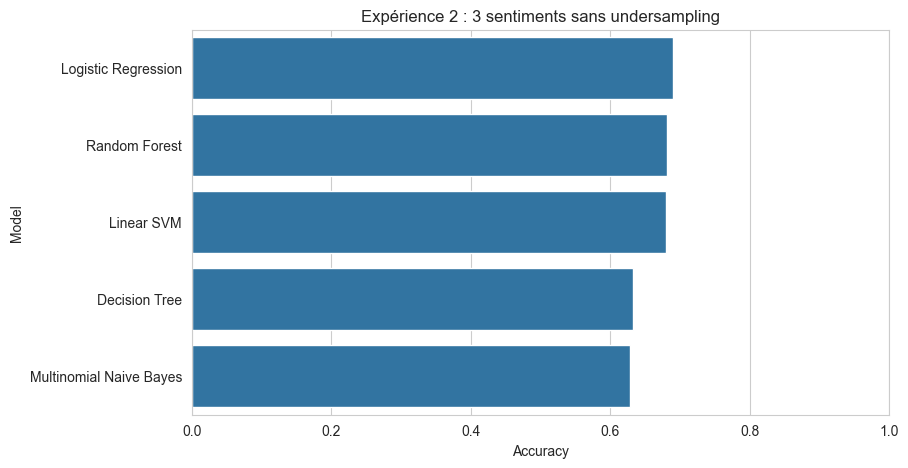

In [17]:
plot_results(results_3, "Expérience 2 : 3 sentiments sans undersampling")

## 2.2 Avec undersampling sur le train

L’undersampling équilibre les classes **uniquement dans le train**. Les ensembles dev et test restent inchangés. Cette opération peut modifier le compromis entre classes; on compare donc les résultats sur les mêmes données de validation.


In [18]:
train_3_balanced = undersample_dataframe(train_single, target_col="sentiment", random_state=42)

print("Avant undersampling :")
print(train_single["sentiment"].value_counts())
print("\nAprès undersampling :")
print(train_3_balanced["sentiment"].value_counts())

X_train_3_bal = train_3_balanced["clean_text"]
y_train_3_bal = train_3_balanced["sentiment"]

results_3_balanced, vectorizer_3_balanced, models_3_balanced = train_and_evaluate(
    X_train_3_bal, y_train_3_bal,
    X_dev_3, y_dev_3,
    max_features=50000,
    ngram_range=(1,2)
)

results_3_balanced

Avant undersampling :
sentiment
neutral     17312
positive    16948
negative     9150
Name: count, dtype: int64

Après undersampling :
sentiment
positive    9150
neutral     9150
negative    9150
Name: count, dtype: int64
Entraînement : Logistic Regression
Entraînement : Multinomial Naive Bayes
Entraînement : Linear SVM
Entraînement : Decision Tree
Entraînement : Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.674714,0.694231,0.674714,0.679183
1,Logistic Regression,0.674346,0.691956,0.674346,0.679525
2,Linear SVM,0.654626,0.669253,0.654626,0.658713
3,Multinomial Naive Bayes,0.619978,0.635378,0.619978,0.623947
4,Decision Tree,0.598784,0.647214,0.598784,0.598751


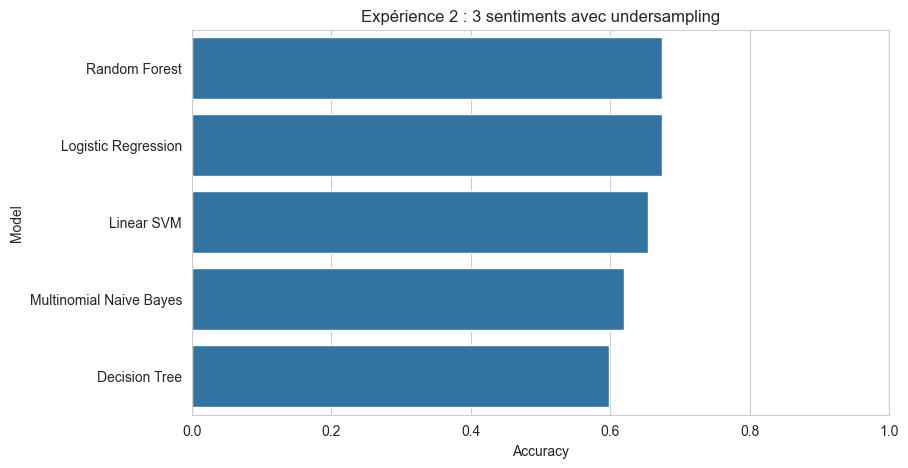

In [19]:
plot_results(results_3_balanced, "Expérience 2 : 3 sentiments avec undersampling")

# Expérience 3 — Classification binaire positive / negative + undersampling

On retire la catégorie `neutral` (qui regroupe ici le label neutral et quatre émotions ambiguës) et on conserve `positive` et `negative`. L’undersampling est appliqué seulement au train.


In [20]:
train_binary = train_single[train_single["sentiment"].isin(["positive", "negative"])].copy()
dev_binary = dev_single[dev_single["sentiment"].isin(["positive", "negative"])].copy()
test_binary = test_single[test_single["sentiment"].isin(["positive", "negative"])].copy()

print("Distribution train binary avant undersampling :")
print(train_binary["sentiment"].value_counts())

train_binary_balanced = undersample_dataframe(train_binary, target_col="sentiment", random_state=42)

print("\nDistribution train binary après undersampling :")
print(train_binary_balanced["sentiment"].value_counts())

Distribution train binary avant undersampling :
sentiment
positive    16948
negative     9150
Name: count, dtype: int64

Distribution train binary après undersampling :
sentiment
negative    9150
positive    9150
Name: count, dtype: int64


In [21]:
X_train_bin = train_binary_balanced["clean_text"]
y_train_bin = train_binary_balanced["sentiment"]

X_dev_bin = dev_binary["clean_text"]
y_dev_bin = dev_binary["sentiment"]

results_binary, vectorizer_binary, models_binary = train_and_evaluate(
    X_train_bin, y_train_bin,
    X_dev_bin, y_dev_bin,
    max_features=50000,
    ngram_range=(1,2)
)

results_binary

Entraînement : Logistic Regression
Entraînement : Multinomial Naive Bayes
Entraînement : Linear SVM
Entraînement : Decision Tree
Entraînement : Random Forest


,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.828804,0.839707,0.828804,0.831462
1,Logistic Regression,0.810688,0.833410,0.810688,0.814740
2,Multinomial Naive Bayes,0.796498,0.814490,0.796498,0.800438
3,Random Forest,0.794384,0.823877,0.794384,0.799134
4,Decision Tree,0.705012,0.785635,0.705012,0.710929


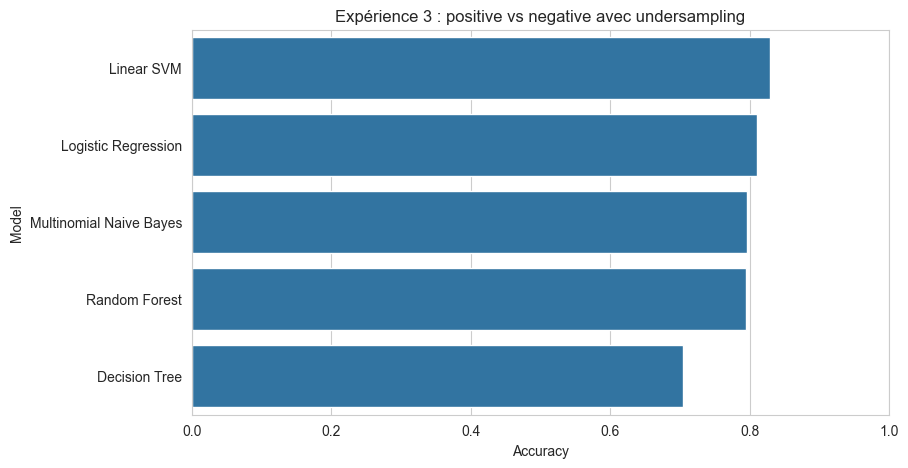

In [22]:
plot_results(results_binary, "Expérience 3 : positive vs negative avec undersampling")

## 7) Comparaison des expériences

Les scores ci-dessous sont calculés sur **dev**. La cible binaire obtient la meilleure accuracy; l’undersampling des trois sentiments équilibre le train mais fait légèrement baisser les scores globaux de validation.


In [23]:
summary_results = pd.DataFrame([
    {
        "Étape": "1) 28 classes (27 émotions + neutral)",
        "Meilleur modèle": results_28.iloc[0]["Model"],
        "Accuracy": results_28.iloc[0]["Accuracy"],
        "F1-score": results_28.iloc[0]["F1-score"]
    },
    {
        "Étape": "2) 3 sentiments",
        "Meilleur modèle": results_3.iloc[0]["Model"],
        "Accuracy": results_3.iloc[0]["Accuracy"],
        "F1-score": results_3.iloc[0]["F1-score"]
    },
    {
        "Étape": "2 bis) 3 sentiments + undersampling",
        "Meilleur modèle": results_3_balanced.iloc[0]["Model"],
        "Accuracy": results_3_balanced.iloc[0]["Accuracy"],
        "F1-score": results_3_balanced.iloc[0]["F1-score"]
    },
    {
        "Étape": "3) Positive / Negative + undersampling",
        "Meilleur modèle": results_binary.iloc[0]["Model"],
        "Accuracy": results_binary.iloc[0]["Accuracy"],
        "F1-score": results_binary.iloc[0]["F1-score"]
    }
])

summary_results

,Étape,Meilleur modèle,Accuracy,F1-score
0,1) 28 classes (27 émotions + neutral),Random Forest,0.507925,0.447442
1,2) 3 sentiments,Logistic Regression,0.689827,0.693210
2,2 bis) 3 sentiments + undersampling,Random Forest,0.674714,0.679183
3,3) Positive / Negative + undersampling,Linear SVM,0.828804,0.831462


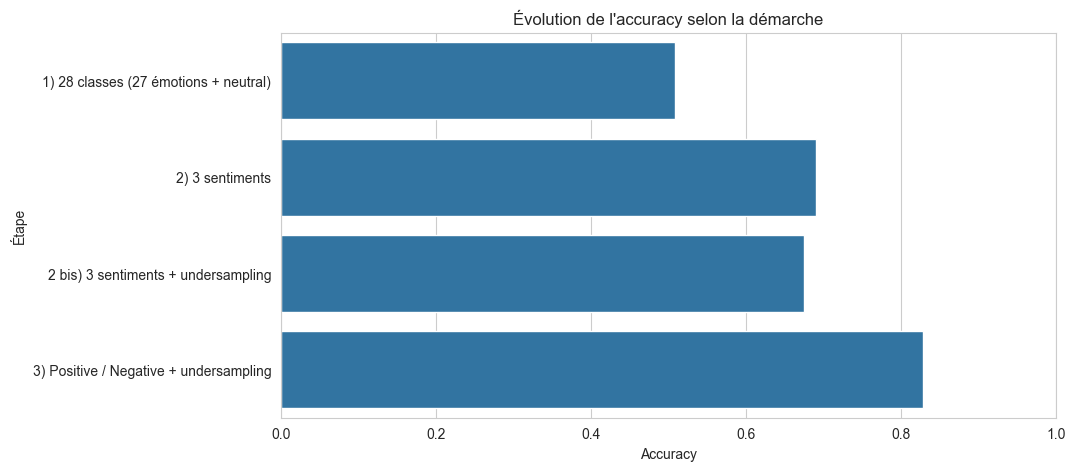

In [24]:
plt.figure(figsize=(10,5))
sns.barplot(data=summary_results, x="Accuracy", y="Étape")
plt.title("Évolution de l'accuracy selon la démarche")
plt.xlim(0, 1)
plt.show()

## 8) Évaluation finale sur le test

Le meilleur modèle de l’expérience binaire est choisi sur **dev**, puis évalué une seule fois sur **test**. Le test binaire contient uniquement les exemples positifs et négatifs.


In [25]:
best_model_name = results_binary.iloc[0]["Model"]
best_model = models_binary[best_model_name]

X_test_bin = test_binary["clean_text"]
y_test_bin = test_binary["sentiment"]
X_test_bin_tfidf = vectorizer_binary.transform(X_test_bin)
y_test_pred = best_model.predict(X_test_bin_tfidf)

print("Meilleur modèle :", best_model_name)
print("Accuracy test :", accuracy_score(y_test_bin, y_test_pred))
print("F1-score test :", f1_score(y_test_bin, y_test_pred, average="weighted", zero_division=0))
print("\nRapport de classification :")
print(classification_report(y_test_bin, y_test_pred, zero_division=0))

Meilleur modèle : Linear SVM
Accuracy test : 0.8229679802955665
F1-score test : 0.8251414312517933

Rapport de classification :
              precision    recall  f1-score   support

    negative       0.72      0.84      0.78      1194
    positive       0.90      0.82      0.85      2054

    accuracy                           0.82      3248
   macro avg       0.81      0.83      0.81      3248
weighted avg       0.83      0.82      0.83      3248



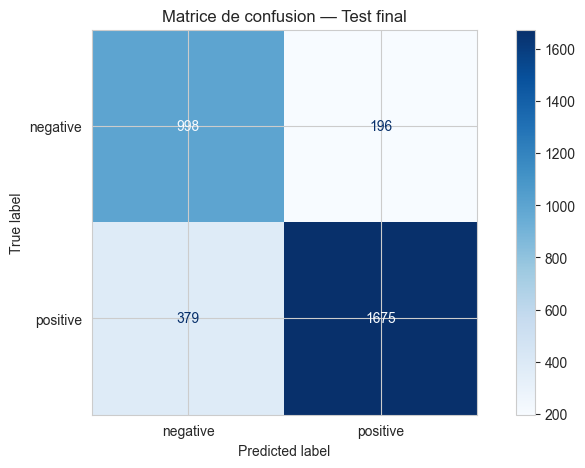

In [26]:
cm = confusion_matrix(y_test_bin, y_test_pred, labels=["negative", "positive"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion — Test final")
plt.show()

## 9) Prédiction sur de nouveaux textes

In [27]:
new_texts = [
    "I am very happy with this result!",
    "This is terrible and disappointing.",
    "I love this project, it is amazing.",
    "I hate this situation."
]

new_texts_clean = [clean_text(t) for t in new_texts]
new_texts_tfidf = vectorizer_binary.transform(new_texts_clean)
predictions = best_model.predict(new_texts_tfidf)

for text, pred in zip(new_texts, predictions):
    print(f"Texte : {text}")
    print(f"Prédiction : {pred}")
    print("---")

Texte : I am very happy with this result!
Prédiction : positive
---
Texte : This is terrible and disappointing.
Prédiction : negative
---
Texte : I love this project, it is amazing.
Prédiction : positive
---
Texte : I hate this situation.
Prédiction : negative
---


## 10) Conclusion

La classification sur 28 labels (27 émotions + neutral) est plus difficile que le regroupement en trois catégories, et la tâche binaire positive/négative obtient les scores de validation les plus élevés. Pour trois classes, l’undersampling rend le train équilibré, mais les scores globaux sur dev diminuent légèrement. Les résultats dépendent donc du mapping de sentiments et de la distribution des classes.
